# Two small-system examples

We reconstruct an eight-qubit chain with three-qubit interactions and a three-by-three lattice. Each example defines its Hamiltonian terms and patches, evolves the system through a four-frame Z-kick cycle, performs patch tomography, and combines the coefficient estimates.

The calculation below uses dense matrix evolution. The helper file contains the evolution, tomography and assembly functions; the steps connecting them are shown here. Run from the repository root in the supplied simulation environment.


In [1]:
from itertools import product
import numpy as np
from scipy.linalg import eigh
import matplotlib.pyplot as plt
import extension_simulations as ext

SEED = 43
SHOT_SEED = 20261118
T = 0.01
KICKS = 12
COPIES = 10_000_000_000

plt.rcParams.update({"font.family": "serif", "font.serif": ["cmr10"],
                     "mathtext.fontset": "cm", "axes.formatter.use_mathtext": True,
                     "font.size": 10, "figure.dpi": 160})


## Reconstruction steps

The coefficients are drawn uniformly from $[-1,1]$. The four-frame cycle has four equal free-evolution intervals, so `KICKS` is a multiple of four. The copy budget counts each global preparation and measurement once, including patches measured in parallel.

The function follows the same steps for both geometries. `assemble` removes the boundary contributions before averaging repeated estimates.


In [2]:
def learn_coefficients(groups, layouts):
    labels = tuple(groups)
    n_sites = len(labels[0])
    target = np.random.default_rng(SEED).uniform(-1, 1, len(labels))
    H = sum(c * ext.kron_all(ext.PAULI_BY_LABEL[p] for p in label)
            for label, c in zip(labels, target))
    energies, vectors = eigh(H)
    free = ext.unitary_from_eigensystem(energies, vectors, T / KICKS)

    settings = [tuple(product(range(4), repeat=max(map(len, layout.patches))))
                for layout in layouts]
    total_settings = sum(len(rows)**2 for rows in settings)
    shots = (COPIES + total_settings - 1) // total_settings
    rng = np.random.default_rng(SHOT_SEED)
    patch_data = {}
    for index, (layout, rows) in enumerate(zip(layouts, settings)):
        frames = ext.frame_signs(n_sites, layout)
        prepared = ext.global_preparations(layout, n_sites, rows)
        evolved = ext.four_frame_evolution(free, frames, KICKS // 4) @ prepared
        _, sampled = ext.finite_patch_data(evolved, layout, n_sites, rows, T, shots, rng)
        ext.record_layout(patch_data, index, sampled)

    rules = ext.assembly_rules(labels, layouts)
    estimate, _ = ext.assemble(patch_data, rules)
    print(f"{len(labels)} coefficients, {len(layouts)} layouts, {shots:,} shots per setting")
    print(f"Total copies: {shots * total_settings:,}")
    return target, estimate


In [3]:
def plot_coefficients(target, estimate, title):
    error = np.abs(estimate - target)
    x = np.arange(len(target))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
    axes[0].scatter(x, target, s=14, facecolors="none", edgecolors="#F79D5C", label="Target")
    axes[0].scatter(x, estimate, s=12, marker="x", color="#9E4D13", label="Reconstructed")
    axes[0].set_ylabel("Coefficient")
    axes[1].scatter(x, error, s=10, color="#9E4D13")
    axes[1].axhline(error.mean(), color="#F79D5C", linestyle="--", label="Mean absolute error")
    axes[1].set_yscale("log")
    axes[1].set_ylabel(r"$|\hat c_j-c_j|$")
    for ax in axes:
        ax.set_xlabel("Coefficient index")
        ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.5)
        ax.legend(fontsize=8)
    fig.suptitle(title)
    plt.show()
    print(f"Mean absolute coefficient error: {error.mean():.6g}")


## Eight-qubit chain

The Hamiltonian includes all Pauli terms whose support fits within three consecutive sites: 24 one-qubit, 117 two-qubit and 162 three-qubit coefficients. Five translated layouts use three-qubit patches and two separator classes. A Pauli string such as `XIIIIIII` acts on the first site only.


In [4]:
chain_groups = ext.chain_coefficients()
chain_layouts = tuple(ext.chain_layout(shift) for shift in range(5))
print("First Pauli terms:", list(chain_groups)[:5])
print("First patch layout:", chain_layouts[0])


First Pauli terms: ['XIIIIIII', 'YIIIIIII', 'ZIIIIIII', 'IXIIIIII', 'IYIIIIII']
First patch layout: Layout(patches=((0, 1, 2), (5, 6, 7)), separators=((3,), (4,)))


303 coefficients, 5 layouts, 488,282 shots per setting
Total copies: 10,000,015,360
Mean absolute coefficient error: 0.0255271


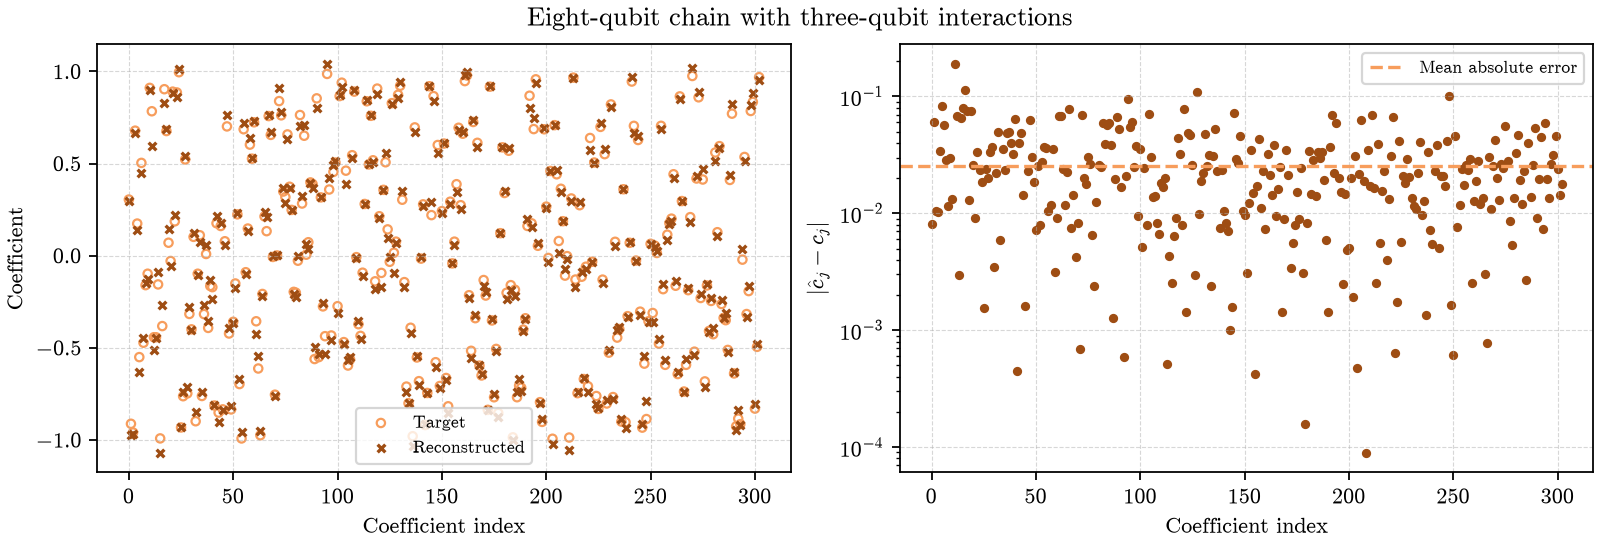

In [5]:
chain = learn_coefficients(chain_groups, chain_layouts)
plot_coefficients(*chain, "Eight-qubit chain with three-qubit interactions")


## Three-by-three square lattice

The open grid has 27 one-qubit and 108 nearest-neighbor two-qubit coefficients. Sites are numbered row by row. Horizontal and vertical patch layouts give 12 scheduled runs; all 12 count toward the copy budget, including the two layouts that coincide at this finite size.


In [6]:
print("Site numbering:")
print(np.arange(9).reshape(3, 3))
lattice_groups = ext.lattice_coefficients()
lattice_schedules = ext.lattice_layouts()
print("First patch layout:", lattice_schedules[0])


Site numbering:
[[0 1 2]
 [3 4 5]
 [6 7 8]]
First patch layout: Layout(patches=((0, 1), (6, 7)), separators=((2, 4, 8), (3, 5)))


135 coefficients, 12 layouts, 4,734,849 shots per setting
Total copies: 10,000,001,088
Mean absolute coefficient error: 0.00978059


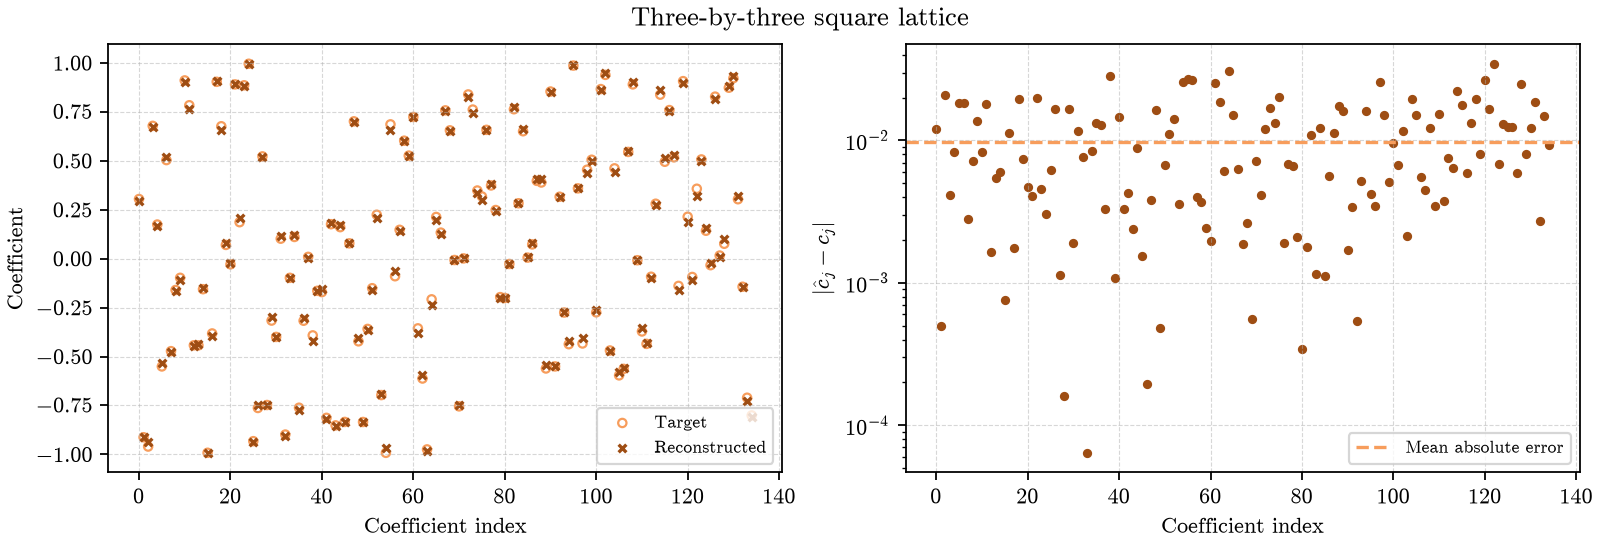

In [7]:
lattice = learn_coefficients(lattice_groups, lattice_schedules)
plot_coefficients(*lattice, "Three-by-three square lattice")


The plotted deviations include both finite-shot fluctuations and finite-kick dynamics. More shots reduce sampling fluctuations; they do not remove the finite-kick contribution. The supplied JSON files in `data/extensions/` contain the reported ten-seed results.
